# 05 · Stacking the neural network with XGBoost, and similar stays

Notebook 02 trained two strong price models: tuned **XGBoost** (14.0% typical error) and our **Keras MLP** with a district embedding (17.6%). The app only used XGBoost. This notebook puts the network to work in two ways.

**1. Stacking.** The two models make different mistakes (trees split on thresholds, the network learns smooth combinations and a learned map of the districts). A small **linear meta-model** learns how much to trust each one:

`stacked log price = a × XGBoost + b × MLP + c`

To keep it honest, the meta-model is trained on **out-of-fold** predictions: every listing is predicted by an XGBoost and an MLP that never saw it. The stacked price replaces the XGBoost-only fair price **only if it beats XGBoost on the test set**.

**2. Similar stays.** The MLP's last hidden layer turns every listing into 64 numbers that summarise what drives its price (size, location, amenities, district). Listings close together in that space are similar stays. The app shows them as "Similar stays".

**Plan**
1. Load the data and the settings found in 02
2. Out-of-fold predictions from XGBoost and the MLP (5 folds)
3. Fit the meta-model on the training rows, compare on the test rows
4. Final models, stacked fair price for every listing
5. Export the network for the app (plain NumPy, so the app needs no TensorFlow)
6. Listing embeddings and similar stays
7. Save

Run after notebooks 01-04, then **run notebook 04 again** (it uses the price gap as an input).

In [1]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path("..").resolve()          # repo root (notebooks/ is one level down)
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"
MODELS = ROOT / "models"
FIGS = ROOT / "reports" / "figures"
for p in (PROCESSED, MODELS, FIGS):
    p.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
SEED = 42

In [2]:
import joblib
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
keras.utils.set_random_seed(SEED)
tf.get_logger().setLevel("ERROR")    # hide TensorFlow's retracing notes

## 1. Data and settings from notebook 02
Same rows (normal stays only), same features and the same 80/20 split as notebook 02. The XGBoost settings come from the saved tuned model, so the random search does not need to run again.

In [3]:
df_all = pd.read_parquet(PROCESSED / "listings_priced.parquet")
feats = json.load(open(PROCESSED / "feature_lists.json"))
CAT, NUM = feats["cat"], feats["num"]

df = df_all[df_all["is_monthly"] == 0].reset_index(drop=True)
X, y = df[CAT + NUM], df["log_price"]
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED)
is_test = np.zeros(len(df), bool); is_test[idx_test] = True
LOG_MIN, LOG_MAX = y.iloc[idx_train].min(), y.iloc[idx_train].max()

xgb_saved = joblib.load(MODELS / "price_model.joblib")      # tuned XGBoost pipeline from notebook 02
print("XGBoost settings:", {k: v for k, v in xgb_saved.named_steps["model"].get_params().items()
                            if k in ("max_depth", "learning_rate", "n_estimators", "min_child_weight",
                                     "subsample", "colsample_bytree", "reg_lambda")})
print(f"normal stays {len(df):,} · train {len(idx_train):,} · test {len(idx_test):,}")

XGBoost settings: {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 8, 'min_child_weight': 1, 'n_estimators': 1200, 'reg_lambda': 10, 'subsample': 0.6}
normal stays 16,436 · train 13,148 · test 3,288


## 2. Out-of-fold predictions
The MLP is the same network as in notebook 02: an 8-number embedding per district, joined with the scaled features and one-hot stay/room type, then Dense 256 → 128 → 64 → 1.
For each of 5 folds both models are trained on the other 4 folds and predict the held-out one, so every listing gets one prediction from each model that never saw it. (The XGBoost part uses the same folds as notebook 02, so its predictions match the fair prices from 02.)

In [4]:
districts = sorted(df_all["neighbourhood_cleansed"].unique())
d2i = {d: i for i, d in enumerate(districts)}
SMALL_CATS = ["stay_type", "room_type"]

class MLPPrep:
    """Scaler + one-hot fitted on one training set; turns a table into the network's two inputs."""
    def __init__(self, Xfit):
        self.scaler = StandardScaler().fit(Xfit[NUM])
        self.onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(Xfit[SMALL_CATS])
    def inputs(self, Xp):
        dist = Xp["neighbourhood_cleansed"].map(d2i).fillna(0).astype("int32").to_numpy()
        num = np.clip(self.scaler.transform(Xp[NUM]), -5, 5)
        dense = np.hstack([num, self.onehot.transform(Xp[SMALL_CATS])]).astype("float32")
        return {"district": dist, "features": dense}

def build_mlp(n_districts, n_dense, emb_dim=8):
    district_in = keras.Input(shape=(), dtype="int32", name="district")
    dense_in = keras.Input(shape=(n_dense,), name="features")
    emb = layers.Embedding(n_districts, emb_dim, name="district_emb")(district_in)
    x = layers.Concatenate()([emb, dense_in])
    l2 = keras.regularizers.l2(1e-4)
    for units, drop in [(256, 0.1), (128, 0.1), (64, 0.0)]:
        x = layers.Dense(units, activation="relu", kernel_regularizer=l2, name=f"dense_{units}")(x)
        if drop:
            x = layers.Dropout(drop)(x)
    out = layers.Dense(1, name="log_price")(x)
    model = keras.Model([district_in, dense_in], out, name="price_mlp")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return model

def fit_mlp(X_fit, y_fit):
    """Trains one MLP (10% of the rows for early stopping). Returns the model, its prep and the target scaling."""
    X_tr, X_val, y_tr, y_val = train_test_split(X_fit, y_fit, test_size=0.1, random_state=SEED)
    prep = MLPPrep(X_tr)
    y_mean, y_std = y_tr.mean(), y_tr.std()
    model = build_mlp(len(districts), prep.inputs(X_tr.iloc[:1])["features"].shape[1])
    model.fit(prep.inputs(X_tr), ((y_tr - y_mean) / y_std).to_numpy(),
              validation_data=(prep.inputs(X_val), ((y_val - y_mean) / y_std).to_numpy()),
              epochs=200, batch_size=128, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
                         keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-5)])
    return model, prep, y_mean, y_std

def predict_mlp(fitted, Xp):
    model, prep, y_mean, y_std = fitted
    return model.predict(prep.inputs(Xp), verbose=0, batch_size=1024).ravel() * y_std + y_mean

In [5]:
# ~5-15 minutes on a laptop: 5 XGBoost + 5 MLP trainings
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
oof_xgb, oof_mlp = np.zeros(len(df)), np.zeros(len(df))
for k, (tr, va) in enumerate(kf.split(X)):
    xgb_k = clone(xgb_saved).fit(X.iloc[tr], y.iloc[tr])
    oof_xgb[va] = xgb_k.predict(X.iloc[va])
    oof_mlp[va] = predict_mlp(fit_mlp(X.iloc[tr], y.iloc[tr]), X.iloc[va])
    print(f"fold {k + 1}: RMSE XGBoost {np.sqrt(mean_squared_error(y.iloc[va], oof_xgb[va])):.3f} · "
          f"MLP {np.sqrt(mean_squared_error(y.iloc[va], oof_mlp[va])):.3f}")
print("correlation of the two models' errors:", np.corrcoef(oof_xgb - y, oof_mlp - y)[0, 1].round(3))

fold 1: RMSE XGBoost 0.307 · MLP 0.358
fold 2: RMSE XGBoost 0.306 · MLP 0.357
fold 3: RMSE XGBoost 0.306 · MLP 0.360
fold 4: RMSE XGBoost 0.305 · MLP 0.365
fold 5: RMSE XGBoost 0.305 · MLP 0.364
correlation of the two models' errors: 0.796


## 3. The meta-model
A linear regression with two inputs (the XGBoost and MLP predictions), fitted on the **training rows only**. The **test rows** were never used to fit it, so they show whether stacking really helps.
A correlation of the two models' errors well below 1 is what makes stacking work: when one model is wrong the other is often less wrong.

In [6]:
results = {}
def evaluate(name, y_true_log, y_pred_log):
    y_pred_log = np.clip(y_pred_log, LOG_MIN, LOG_MAX)
    y_true, y_pred = np.exp(y_true_log), np.exp(y_pred_log)
    results[name] = {
        "RMSE_log": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        "MAE_TRY": mean_absolute_error(y_true, y_pred),
        "MedianAPE_%": np.median(np.abs(y_pred / y_true - 1)) * 100,
        "R2_log": r2_score(y_true_log, y_pred_log),
    }

L1 = np.column_stack([oof_xgb, oof_mlp])
meta = LinearRegression().fit(L1[~is_test], y[~is_test])
stack_oof = meta.predict(L1)
print(f"meta-model: {meta.coef_[0]:.3f} × XGBoost + {meta.coef_[1]:.3f} × MLP + {meta.intercept_:.3f}")

yt = y[is_test]
evaluate("XGBoost (tuned)", yt, oof_xgb[is_test])
evaluate("MLP (ours)", yt, oof_mlp[is_test])
evaluate("Simple average", yt, L1[is_test].mean(axis=1))
evaluate("Stacked (XGBoost + MLP)", yt, stack_oof[is_test])
res = pd.DataFrame(results).T.sort_values("RMSE_log")
res.round(3)

meta-model: 0.898 × XGBoost + 0.128 × MLP + -0.219


,RMSE_log,MAE_TRY,MedianAPE_%,R2_log
Stacked (XGBoost + MLP),0.306,1349.751,14.288,0.756
XGBoost (tuned),0.307,1350.463,14.294,0.753
Simple average,0.315,1402.339,14.786,0.741
MLP (ours),0.358,1605.164,17.449,0.665


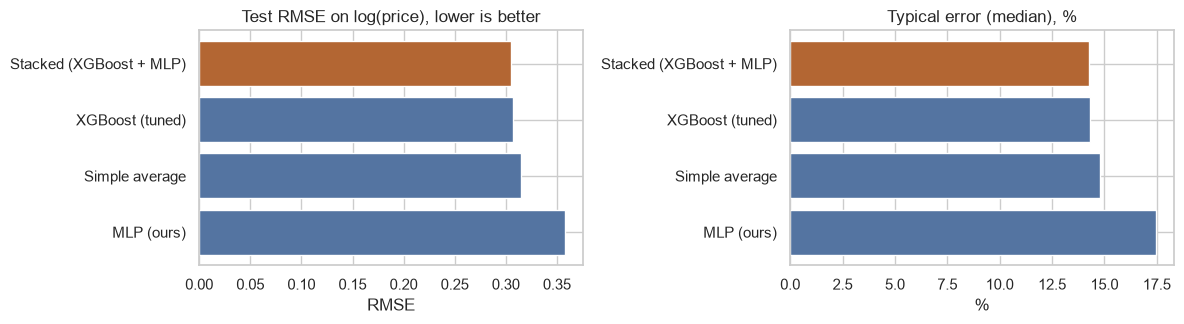

use the stacked price: True (typical error +0.01 points vs XGBoost alone)


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
order = res.sort_values("RMSE_log", ascending=False)
colors = ["#b36633" if n.startswith("Stacked") else "#5474a1" for n in order.index]
ax[0].barh(order.index, order["RMSE_log"], color=colors); ax[0].set(title="Test RMSE on log(price), lower is better", xlabel="RMSE")
ax[1].barh(order.index, order["MedianAPE_%"], color=colors); ax[1].set(title="Typical error (median), %", xlabel="%")
plt.tight_layout(); plt.savefig(FIGS / "stacking_comparison.png", dpi=120); plt.show()

USE_STACK = results["Stacked (XGBoost + MLP)"]["RMSE_log"] < results["XGBoost (tuned)"]["RMSE_log"]
gain = results["XGBoost (tuned)"]["MedianAPE_%"] - results["Stacked (XGBoost + MLP)"]["MedianAPE_%"]
print("use the stacked price:", USE_STACK, f"(typical error {gain:+.2f} points vs XGBoost alone)")

## 4. Final models and the fair price
* Normal stays: fair price = the meta-model applied to the out-of-fold predictions (every listing priced by models that never saw it).
* Monthly-style listings: final XGBoost (the saved model from 02) and a final MLP trained on all normal stays.
* The meta-model is refit on all normal stays for the final weights.
The XGBoost-only fair price is kept as `fair_price_xgb` for comparison.

In [8]:
meta_final = LinearRegression().fit(L1, y)
mlp_final = fit_mlp(X, y)                 # all normal stays
X_all = df_all[CAT + NUM]
xgb_all = xgb_saved.predict(X_all)
mlp_all = predict_mlp(mlp_final, X_all)

if "fair_price_xgb" not in df_all:        # first run: keep notebook 02's XGBoost fair price
    df_all["fair_price_xgb"] = df_all["fair_price"]
normal = (df_all["is_monthly"] == 0).to_numpy()
if USE_STACK:
    stacked = meta_final.predict(np.column_stack([xgb_all, mlp_all]))
    stacked[normal] = meta_final.predict(L1)      # out-of-fold for the listings the models trained on
    df_all["fair_price"] = np.exp(np.clip(stacked, LOG_MIN, LOG_MAX))
else:
    df_all["fair_price"] = df_all["fair_price_xgb"]
df_all["price_gap"] = (df_all["fair_price"] - df_all["price"]) / df_all["fair_price"]
print(f"final meta-model: {meta_final.coef_[0]:.3f} × XGBoost + {meta_final.coef_[1]:.3f} × MLP + {meta_final.intercept_:.3f}")
df_all[["price", "fair_price_xgb", "fair_price", "price_gap"]].describe().round(2)

final meta-model: 0.890 × XGBoost + 0.133 × MLP + -0.194


,price,fair_price_xgb,fair_price,price_gap
count,24190.00,24190.00,24190.00,24190.00
mean,5109.83,4981.29,4981.34,-0.01
std,5221.05,3420.49,3488.36,0.85
min,417.28,640.00,640.00,-29.71
25%,2341.00,2900.86,2878.65,-0.11
50%,3730.00,4066.02,4040.24,0.06
75%,6055.70,5884.39,5876.45,0.27
max,55730.00,46871.01,47458.66,0.95


## 5. Export the network for the app
The app should not need TensorFlow just to run one small network. A Dense layer is only `relu(x @ W + b)`, so the weights are saved as NumPy arrays and the app's "Check a price" form runs the same maths. The check below confirms the NumPy version gives the same answer as Keras.

In [9]:
model, prep, y_mean, y_std = mlp_final
dense_layers = [l for l in model.layers if isinstance(l, layers.Dense)]
export = {
    "emb": model.get_layer("district_emb").get_weights()[0],
    "dense": [(l.get_weights()[0], l.get_weights()[1]) for l in dense_layers],
    "scaler": prep.scaler, "onehot": prep.onehot, "districts": districts,
    "num": NUM, "small_cats": SMALL_CATS, "y_mean": float(y_mean), "y_std": float(y_std),
    "meta_coef": meta_final.coef_.tolist(), "meta_intercept": float(meta_final.intercept_),
    "use_stack": bool(USE_STACK), "log_min": float(LOG_MIN), "log_max": float(LOG_MAX),
    "test_scores": {k: {m: float(v) for m, v in r.items()} for k, r in results.items()},
}

def mlp_numpy(e, Xp):
    """The network's forward pass in plain NumPy (what the app runs)."""
    d2i_ = {d: i for i, d in enumerate(e["districts"])}
    dist = Xp["neighbourhood_cleansed"].map(d2i_).fillna(0).astype(int).to_numpy()
    num = np.clip(e["scaler"].transform(Xp[e["num"]]), -5, 5)
    h = np.hstack([e["emb"][dist], num, e["onehot"].transform(Xp[e["small_cats"]])])
    for i, (W, b) in enumerate(e["dense"]):
        h = h @ W + b
        if i < len(e["dense"]) - 1:
            h = np.maximum(h, 0)
    return h.ravel() * e["y_std"] + e["y_mean"]

check = X_all.sample(500, random_state=SEED)
print("largest difference NumPy vs Keras (log price):",
      np.abs(mlp_numpy(export, check) - predict_mlp(mlp_final, check)).max())
joblib.dump(export, MODELS / "price_stack.joblib")
model.save(MODELS / "price_mlp_full.keras")

largest difference NumPy vs Keras (log price): 4.1878253220772876e-07


## 6. Listing embeddings and similar stays
The output of the 64-unit layer is the network's own description of a listing. Two listings with nearby vectors look alike to the network: similar size, comfort, location and district, so a similar fair price.
For every listing we keep the 5 nearest listings (straight-line distance between the vectors) among the stays the app shows (active, or likely active by the reliability model from notebook 04).

In [10]:
embedder = keras.Model(model.inputs, model.get_layer("dense_64").output)
E = embedder.predict(prep.inputs(X_all), verbose=0, batch_size=1024)
print("embedding matrix:", E.shape)

shown = ((df_all["active_ltm"] == 1) | (df_all["reliability"] >= 0.5)).to_numpy() if "reliability" in df_all \
        else np.ones(len(df_all), bool)
pool = np.flatnonzero(shown)
nn = NearestNeighbors(n_neighbors=6).fit(E[pool])     # Euclidean: kept closer prices and guest counts than cosine
dist, ind = nn.kneighbors(E)
ids = df_all["id"].to_numpy()
similar = []
for i in range(len(df_all)):
    cand = [pool[j] for j in ind[i] if pool[j] != i][:5]
    similar.append(ids[cand].tolist())
df_all["similar_ids"] = similar

# a look at one example: the listing and its 5 neighbours
ex = df_all.index[(df_all["number_of_reviews"] > 20) & shown][0]
cols = ["name", "neighbourhood_cleansed", "stay_type", "accommodates", "bedrooms", "price", "fair_price"]
pd.concat([df_all.loc[[ex], cols].assign(role="listing"),
           df_all.set_index("id").loc[df_all.at[ex, "similar_ids"]].reset_index()[cols].assign(role="similar")])

embedding matrix: (24190, 64)


,name,neighbourhood_cleansed,stay_type,accommodates,bedrooms,price,fair_price,role
5,Sea view Family Suite Sultanahmet,Fatih,Entire home,5,1.0,6302.0,5986.738288,listing
0,Stylish Flat w/ Balcony – 5 Mins from Taksim,Beyoglu,Entire home,5,2.0,6712.5,4860.075962,similar
1,Spacious & bright 2+1 on a calm st.,Kadikoy,Entire home,4,2.0,5071.5,5892.690467,similar
2,"Lovely Bright Large 2-Beds Flat with Balcony, ...",Kadikoy,Entire home,4,2.0,5021.5,7591.494114,similar
3,2BR Rooftop Duplex W/Private Terrace in Cihangir,Beyoglu,Entire home,4,2.0,5963.5,6907.780381,similar
4,2BR Haven W/Magnificent Bosphorus View in Ciha...,Beyoglu,Entire home,4,2.0,7050.0,7466.686225,similar


In [11]:
# How alike are the neighbours? Compare with 5 random listings, for 2,000 listings.
rng = np.random.default_rng(SEED)
sample = rng.choice(pool, 2000, replace=False)
pos = pd.Series(np.arange(len(df_all)), index=df_all["id"])
lp, ll = df_all["log_price"].to_numpy(), df_all[["latitude", "longitude"]].to_numpy()
ac, st_ = df_all["accommodates"].to_numpy(), df_all["stay_type"].to_numpy()
def alike(i, js):
    return (np.abs(lp[js] - lp[i]).mean(),                                   # price gap on the log scale
            np.hypot(*((ll[js] - ll[i]) * [111, 84]).T).mean(),             # km apart (1° ≈ 111 km N-S, 84 km E-W here)
            np.abs(ac[js] - ac[i]).mean(), (st_[js] == st_[i]).mean())
nb = np.array([alike(i, pos[df_all.at[i, "similar_ids"]].to_numpy()) for i in sample])
rd = np.array([alike(i, rng.choice(pool, 5)) for i in sample])
pd.DataFrame({"similar stays": nb.mean(0), "random stays": rd.mean(0)},
             index=["price difference (log)", "distance (km)", "guest difference", "same stay type (share)"]).round(3)

,similar stays,random stays
price difference (log),0.194,0.693
distance (km),3.981,10.695
guest difference,0.762,2.129
same stay type (share),0.822,0.487


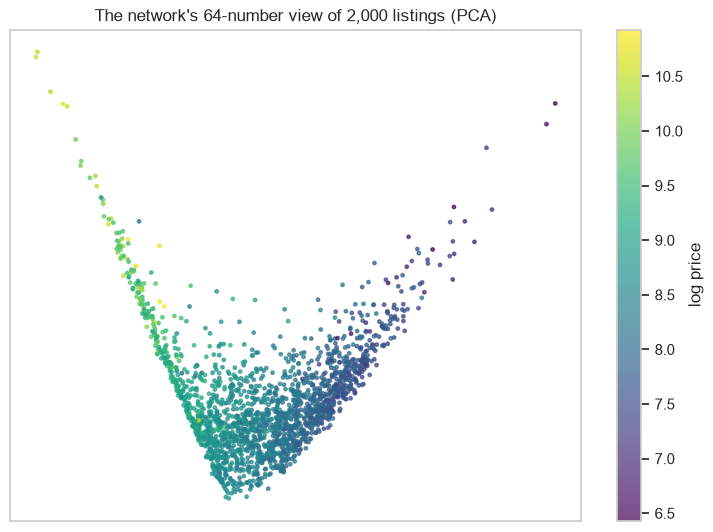

In [12]:
xy = PCA(2, random_state=SEED).fit_transform(E[sample])
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sc = ax.scatter(xy[:, 0], xy[:, 1], c=lp[sample], cmap="viridis", s=6, alpha=.7)
plt.colorbar(sc, label="log price")
ax.set(title="The network's 64-number view of 2,000 listings (PCA)", xticks=[], yticks=[])
plt.tight_layout(); plt.savefig(FIGS / "mlp_listing_embeddings.png", dpi=120); plt.show()

## 7. Save
`listings_priced.parquet` now has the stacked `fair_price` and `price_gap`, the old `fair_price_xgb`, and `similar_ids`.
**Next: run notebook 04 again**, so the reliability model uses the new price gap.

In [13]:
df_all.to_parquet(PROCESSED / "listings_priced.parquet", index=False)
print("saved", df_all.shape)
res.round(3)

saved (24190, 75)


,RMSE_log,MAE_TRY,MedianAPE_%,R2_log
Stacked (XGBoost + MLP),0.306,1349.751,14.288,0.756
XGBoost (tuned),0.307,1350.463,14.294,0.753
Simple average,0.315,1402.339,14.786,0.741
MLP (ours),0.358,1605.164,17.449,0.665
